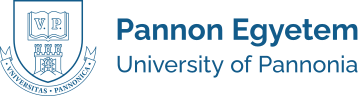

# Konfigurációkezelés: nyilvántartás, hatásterjedés a konfigurációs elemek között, a besorolás ellenőrzése

A notebook

1. betölti a konfigurációs elemeket (CI), a köztük lévő hatáskapcsolatokat és a változáskérelmeket;
2. elkészíti a nyilvántartást: besorolás (jelentős / kisebb / eltérési engedély), döntéshozó, állapot, átfutási idők;
3. a kapcsolatok gráfján kiszámolja, hogy egy változtatás hatása mely elemekig terjedhet, és megmutatja, melyeket nem vizsgálta még a hatáselemzés;
4. összeveti a hatásjellemzőket (biztonság, interfész, képzés, specifikáció) a megjelölt elemekkel, és jelzi az ellentmondásokat;
5. ábrán mutatja egy kérelem hatásterjedését és a kérelmek átfutását.

A beépített példa a KoboCella konfigurációkezelése (kézikönyv 26. fejezet; ISO 10007:2017; MIL-HDBK-61B, 2020; NASA SE Handbook, 6.5. szakasz).

[Megnyitás Google Colabban](https://colab.research.google.com/github/ComplexSystemsIntelligence/rendszermernokseg/blob/main/gyakorlat/notebookok/konfiguracio.ipynb) · Rendszermérnöki eszköztár – Gyakorlati útmutató · Abonyi János · CC BY-NC-SA 4.0 (szöveg), MIT (kód)

**Használat.** Futtasd a cellákat sorban (Colabban: *Futtatókörnyezet → Összes futtatása*). A notebook alapértelmezésben a beépített példaadatokkal dolgozik.
Saját adataidhoz töltsd ki a [`konfiguracio_sablon.xlsx`](https://complexsystemsintelligence.github.io/rendszermernokseg/gyakorlat/sablonok/konfiguracio_sablon.xlsx) sablont, állítsd a `SAJAT_SABLON` változót `True` értékre, és futtatáskor töltsd fel a fájlt.

A módszer leírása és értelmezése: Gyakorlati útmutató, Konfigurációkezelés és változáskérelem eszközlap.

In [ ]:
SAJAT_SABLON = False   # True: a kitöltött konfiguracio_sablon.xlsx

import sys, os
COLABBAN = "google.colab" in sys.modules

def sablon_betoltese(alapnev):
    """Visszaadja a feltöltött vagy a notebook mellett lévő sablon útvonalát."""
    if COLABBAN:
        from google.colab import files
        print("Válaszd ki a kitöltött sablont:")
        feltoltott = files.upload()
        return next(iter(feltoltott))
    for jelolt in (alapnev, os.path.join("..", "sablonok", alapnev)):
        if os.path.exists(jelolt):
            return jelolt
    raise FileNotFoundError(f"Nem találom: {alapnev}")

import datetime
from collections import deque
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

## Adatok

In [ ]:
JELL = ['Alapvonal, specifikáció', 'Költség', 'Biztonság', 'Interfész', 'Képzés', 'Leszállított termék']
if SAJAT_SABLON:
    fajl = sablon_betoltese("konfiguracio_sablon.xlsx")
    ci = pd.read_excel(fajl, sheet_name="Konfigurációs elemek", header=3).iloc[:25, :8]
    ci.columns = ["id", "nev", "tipus", "alapvonal", "valtozat", "allapot", "felelos", "hely"]
    ci = ci[ci.id.notna()].reset_index(drop=True)
    km = pd.read_excel(fajl, sheet_name="Kapcsolatok", header=None).iloc[4:4 + len(ci), 2:2 + len(ci)]
    elek = [(ci.id[i], ci.id[j]) for i in range(len(ci)) for j in range(len(ci))
            if str(km.iat[i, j]).strip().lower() == "x"]
    vk = pd.read_excel(fajl, sheet_name="Változáskérelmek", header=3).iloc[:20, :16]
    vk.columns = ["id", "cim", "fajta", "kezdemenyezo", "beadva"] + JELL + ["_o", "_d", "dontes", "dontes_datum", "lezarva"]
    vk = vk[vk.id.notna()].drop(columns=["_o", "_d"]).reset_index(drop=True)
    hm = pd.read_excel(fajl, sheet_name="Hatásmátrix", header=None).iloc[4:4 + len(ci), 2:2 + len(vk)]
    hatas = {vk.id[k]: {ci.id[i]: str(hm.iat[i, k]).strip().lower() for i in range(len(ci))
                        if str(hm.iat[i, k]).strip().lower() in ("x", "n")} for k in range(len(vk))}
    ertekeles = pd.Timestamp(pd.read_excel(fajl, sheet_name="Összesítés", header=None).iat[2, 1])
else:
    ci = pd.DataFrame([('CI-01', 'Rendszerkövetelmény-specifikáció', 'dokumentum', 'funkcionális', '2.1', 'alapvonalban', 'rendszermérnök', 'PLM/követelmények'), ('CI-02', 'Rendszerarchitektúra', 'dokumentum', 'allokált', '1.3', 'alapvonalban', 'rendszermérnök', 'PLM/architektúra'), ('CI-03', 'ICD I-06: kezelő–kezelőfelület', 'dokumentum', 'allokált', '1.2', 'alapvonalban', 'ergonómus', 'PLM/interfészek'), ('CI-04', 'ICD I-07: csavarozó vezérlő–MES', 'dokumentum', 'allokált', '0.4', 'tervezet', 'informatikus', 'PLM/interfészek'), ('CI-05', 'Kockázatértékelés és biztonsági igazolás', 'dokumentum', 'allokált', '1.2', 'alapvonalban', 'biztonsági mérnök', 'PLM/biztonság'), ('CI-06', 'Cellavezérlő PLC-programja', 'szoftver', 'termék', '3.5', 'alapvonalban', 'automatizálási mérnök', 'Git/plc'), ('CI-07', 'Kobotprogram', 'szoftver', 'termék', '2.7', 'módosítás alatt', 'robotprogramozó', 'Git/kobot'), ('CI-08', 'Biztonsági PLC programja', 'szoftver', 'termék', '1.5', 'alapvonalban', 'biztonsági mérnök', 'Git/safety'), ('CI-09', 'Kezelőfelület-alkalmazás (HMI)', 'szoftver', 'termék', '2.3', 'alapvonalban', 'automatizálási mérnök', 'Git/hmi'), ('CI-10', 'Csavarozási paraméterkészlet', 'adat', 'termék', '1.8', 'alapvonalban', 'technológus', 'Git/csavarozo'), ('CI-11', 'Befogó készülék gyártási rajzai', 'hardver', 'termék', 'rev. D', 'alapvonalban', 'gépészmérnök', 'PLM/rajzok'), ('CI-12', 'Villamos kapcsolási rajz', 'hardver', 'termék', 'rev. E', 'alapvonalban', 'villamosmérnök', 'PLM/rajzok'), ('CI-13', 'Tervezési FMEA', 'dokumentum', 'termék', '1.5', 'alapvonalban', 'minőségügyi mérnök', 'PLM/kockázat'), ('CI-14', 'Kezelési útmutató', 'dokumentum', 'termék', '1.4', 'alapvonalban', 'ergonómus', 'PLM/dokumentáció'), ('CI-15', 'Feladatelemzés (HTA)', 'dokumentum', 'allokált', '1.2', 'alapvonalban', 'ergonómus', 'PLM/ember-gép'), ('CI-16', 'Képzési anyag', 'dokumentum', 'termék', '1.1', 'alapvonalban', 'műszakvezető', 'PLM/dokumentáció'), ('CI-17', 'Karbantartási utasítás', 'dokumentum', 'termék', '1.1', 'alapvonalban', 'karbantartási vezető', 'PLM/dokumentáció'), ('CI-18', 'Verifikációs mátrix (RVM)', 'dokumentum', 'termék', '1.7', 'alapvonalban', 'rendszermérnök', 'PLM/verifikáció')],
                      columns=["id", "nev", "tipus", "alapvonal", "valtozat", "allapot", "felelos", "hely"])
    kapcs = {'CI-01': ['CI-02', 'CI-18'], 'CI-02': ['CI-03', 'CI-04', 'CI-05', 'CI-12'], 'CI-03': ['CI-09', 'CI-12', 'CI-14', 'CI-15'], 'CI-04': ['CI-06', 'CI-10', 'CI-18'], 'CI-05': ['CI-08', 'CI-14', 'CI-16'], 'CI-06': ['CI-18'], 'CI-07': ['CI-05', 'CI-18'], 'CI-08': ['CI-05', 'CI-18'], 'CI-09': ['CI-14', 'CI-18'], 'CI-10': ['CI-18'], 'CI-11': ['CI-07', 'CI-13', 'CI-17'], 'CI-12': ['CI-06', 'CI-08', 'CI-17'], 'CI-13': ['CI-05', 'CI-17'], 'CI-14': ['CI-16'], 'CI-15': ['CI-14', 'CI-16'], 'CI-17': ['CI-16']}
    elek = [(a, b) for a, cel in kapcs.items() for b in cel]
    _vk = [('CR-001', 'Mértékegység-elírás javítása a követelményspecifikációban (R-07)', 'változtatás', 'minőségügyi mérnök', datetime.date(2026, 1, 12), ['nem', 'nem', 'nem', 'nem', 'nem', 'nem'], 'jóváhagyva', datetime.date(2026, 1, 13), datetime.date(2026, 1, 16)), ('CR-002', 'Kopásálló betét a befogó ütközőjén', 'változtatás', 'karbantartási vezető', datetime.date(2026, 2, 2), ['nem', 'nem', 'nem', 'nem', 'nem', 'nem'], 'jóváhagyva', datetime.date(2026, 2, 5), datetime.date(2026, 2, 27)), ('CR-003', 'Második nyugtázó gomb a kezelői oldalon', 'változtatás', 'validációs csoport', datetime.date(2026, 3, 10), ['nem', 'nem', 'nem', 'igen', 'igen', 'nem'], 'jóváhagyva', datetime.date(2026, 3, 17), datetime.date(2026, 4, 14)), ('CR-004', 'Kobotpálya módosítása a ciklusidő csökkentésére', 'változtatás', 'technológus', datetime.date(2026, 4, 8), ['nem', 'nem', 'igen', 'nem', 'nem', 'nem'], 'jóváhagyva', datetime.date(2026, 4, 15), None), ('CR-005', 'Elírások javítása a kezelési útmutatóban', 'változtatás', 'műszakvezető', datetime.date(2026, 4, 13), ['nem', 'nem', 'nem', 'nem', 'nem', 'nem'], 'jóváhagyva', datetime.date(2026, 4, 14), datetime.date(2026, 4, 17)), ('CR-006', 'Szériaszám mező a csavarozási adatokban (I-07)', 'változtatás', 'informatikus', datetime.date(2026, 5, 4), ['nem', 'nem', 'nem', 'igen', 'nem', 'nem'], 'függőben', None, None), ('CR-007', 'Üzem MES-kapcsolat nélkül négy hétig, kézi adatrögzítéssel', 'eltérési engedély', 'projektvezető', datetime.date(2026, 4, 22), ['nem', 'nem', 'nem', 'nem', 'nem', 'nem'], 'jóváhagyva', datetime.date(2026, 4, 24), None)]
    vk = pd.DataFrame([list(v[:5]) + list(v[5]) + list(v[6:9]) for v in _vk],
                      columns=["id", "cim", "fajta", "kezdemenyezo", "beadva"] + JELL + ["dontes", "dontes_datum", "lezarva"])
    hatas = {'CR-001': {'CI-01': 'x', 'CI-02': 'n', 'CI-18': 'n'}, 'CR-002': {'CI-11': 'x', 'CI-13': 'x', 'CI-17': 'x', 'CI-07': 'n', 'CI-16': 'n', 'CI-05': 'n'}, 'CR-003': {'CI-03': 'x', 'CI-09': 'x', 'CI-12': 'x', 'CI-06': 'x', 'CI-14': 'x', 'CI-15': 'x', 'CI-16': 'x', 'CI-18': 'x', 'CI-05': 'n', 'CI-08': 'n', 'CI-17': 'n'}, 'CR-004': {'CI-07': 'x'}, 'CR-005': {'CI-14': 'x', 'CI-16': 'n'}, 'CR-006': {'CI-04': 'x', 'CI-10': 'x'}, 'CR-007': {}}
    ertekeles = pd.Timestamp(datetime.date(2026, 5, 18))
for c in ("beadva", "dontes_datum", "lezarva"):
    vk[c] = pd.to_datetime(vk[c], errors="coerce")
nev = dict(zip(ci.id, ci.nev))
print(f"{len(ci)} konfigurációs elem, {len(elek)} hatáskapcsolat, {len(vk)} kérelem")

## Nyilvántartás

A MIL-HDBK-61B szerint a változás **jelentős** (I. osztályú), ha érinti a specifikációt, a költséget, a biztonságot, az interfészekkel való összeférhetőséget, a kezelők vagy karbantartók képzését, vagy utólagos átalakítást kíván a leszállított termékeken; egyébként **kisebb** (II. osztályú). A jelentős változásokról a konfigurációs bizottság dönt. Az eltérési engedély nem változtatja meg az alapvonalat.

In [ ]:
def osztaly(r):
    if r.fajta == "eltérési engedély":
        return "eltérési engedély"
    return "jelentős" if any(str(r[j]).strip().lower() == "igen" for j in JELL) else "kisebb"

def allapot(r):
    if r.dontes == "elutasítva":
        return "elutasítva"
    if pd.notna(r.lezarva):
        return "lezárt"
    if r.dontes == "jóváhagyva":
        return "érvényben" if r.fajta == "eltérési engedély" else "végrehajtás alatt"
    return "döntésre vár"

vk["osztaly"] = vk.apply(osztaly, axis=1)
vk["donteshozo"] = np.where(vk.osztaly == "kisebb", "konfigurációs vezető", "konfigurációs bizottság")
vk["allapot"] = vk.apply(allapot, axis=1)
vk["dontesig"] = (vk.dontes_datum - vk.beadva).dt.days
vk["atfutas"] = (vk.lezarva - vk.beadva).dt.days
nyitott = vk.allapot.isin(["döntésre vár", "végrehajtás alatt"])
vk["nyitva"] = np.where(nyitott, (ertekeles - vk.beadva).dt.days, np.nan)
display(vk[["id", "cim", "osztaly", "donteshozo", "allapot", "dontesig", "atfutas", "nyitva"]])
print(pd.crosstab(vk.osztaly, vk.allapot, margins=True, margins_name="összesen"))
print("\nÁtlagos napok osztályonként:")
print(vk.groupby("osztaly")[["dontesig", "atfutas"]].mean().round(1))

## Hatásterjedés a konfigurációs elemek között

A kapcsolatok irányított gráfot alkotnak: a *forrás → cél* él azt jelenti, hogy a forrás módosítása után a célt ellenőrizni kell. Egy kérelem módosítandó elemeiből (x) kiindulva szélességi bejárással megkeressük, mely elemekig terjedhet a hatás. A már megvizsgált, nem érintett elemeken (n) a bejárás megáll, a még nem vizsgáltakon továbbhalad: ezek **potenciálisan érintettek**, amíg valaki meg nem vizsgálja őket. A sablon csak a közvetlen (1. szintű) hatást jelzi; a notebook a teljes láncot és a távolságot is megadja.

In [ ]:
G = nx.DiGraph()
G.add_nodes_from(ci.id)
G.add_edges_from(elek)

def hatasterjedes(jelolesek):
    x = {c for c, j in jelolesek.items() if j == "x"}
    n = {c for c, j in jelolesek.items() if j == "n"}
    tav = {}
    sor = deque((c, 0) for c in x)
    latott = set(x)
    while sor:
        v, d = sor.popleft()
        for w in G.successors(v):
            if w in latott:
                continue
            latott.add(w)
            if w in n:
                continue                 # megvizsgálva, nem érinti: itt megáll a hatás
            tav[w] = d + 1
            sor.append((w, d + 1))
    return x, n, tav

sorok = []
for k, r in vk.iterrows():
    x, n, tav = hatasterjedes(hatas.get(r.id, {}))
    sorok.append({"kérelem": r.id, "állapot": r.allapot, "módosítandó": len(x), "nem érinti": len(n),
                  "ellenőrizetlen, közvetlen": sum(1 for d in tav.values() if d == 1),
                  "ellenőrizetlen, összesen": len(tav),
                  "ellenőrizendő elemek": ", ".join(f"{c} ({d})" for c, d in sorted(tav.items(), key=lambda t: (t[1], t[0])))})
terj = pd.DataFrame(sorok)
display(terj)

## A besorolás és a hatáselemzés összevetése

Két egyszerű szabály:

- **A:** ha egy hatásjellemző „igen” (például biztonság), az ehhez tartozó elemet (a biztonsági igazolást) a hatáselemzésnek meg kell vizsgálnia;
- **B:** ha egy ilyen elem módosul, de a hozzá tartozó jellemző „nem”, a besorolást indokolni kell (például szerkesztési javítás a specifikációban).

Az elemek szerepét a megnevezésükből soroljuk be; saját projektben ezt a táblázatot érdemes kézzel megadni.

In [ ]:
SZEREP = {"Biztonság": ["biztonsági igazolás", "kockázatértékelés"], "Interfész": ["icd", "interfész"],
          "Képzés": ["képzési anyag"], "Alapvonal, specifikáció": ["követelmény-specifikáció", "specifikáció"]}
szerep = {j: {c for c, m in nev.items() if any(s in str(m).lower() for s in kulcsok)} for j, kulcsok in SZEREP.items()}
print({j: sorted(s) for j, s in szerep.items()})

figy = []
for _, r in vk[vk.fajta != "eltérési engedély"].iterrows():
    jel = hatas.get(r.id, {})
    x = {c for c, j in jel.items() if j == "x"}
    vizsgalt = set(jel)
    for j, elemek in szerep.items():
        igen = str(r[j]).strip().lower() == "igen"
        if igen and elemek and not (elemek & vizsgalt):
            figy.append((r.id, "A", f"{j} = igen, de {', '.join(sorted(elemek))} nincs megvizsgálva"))
        if not igen and elemek & x:
            figy.append((r.id, "B", f"{', '.join(sorted(elemek & x))} módosul, de {j} = nem: indokold a besorolást"))
display(pd.DataFrame(figy, columns=["kérelem", "szabály", "megállapítás"]))

## Ábra: egy kérelem hatásterjedése és a kérelmek átfutása

In [ ]:
# a legtöbb ellenőrizetlen elemet hagyó nyitott kérelem (ha nincs ilyen, az első)
jelolt = terj[terj["állapot"].isin(["döntésre vár", "végrehajtás alatt"])].sort_values("ellenőrizetlen, összesen", ascending=False)
PELDA = jelolt["kérelem"].iloc[0] if len(jelolt) else vk.id.iloc[0]
x, n, tav = hatasterjedes(hatas.get(PELDA, {}))

# rétegek: leghosszabb út a kölcsönösen ható elemcsoportok összevonása után; rétegen belül baricentrum-sorrend
C = nx.condensation(G)
retegC = {}
for v in nx.topological_sort(C):
    retegC[v] = max((retegC[u] + 1 for u in C.predecessors(v)), default=0)
reteg = {c: retegC[C.graph["mapping"][c]] for c in G}
retegek = {}
for c in G:
    retegek.setdefault(reteg[c], []).append(c)
y = {c: i - (len(l) - 1) / 2 for l in retegek.values() for i, c in enumerate(l)}
for _ in range(6):
    for r in sorted(retegek):
        l = retegek[r]
        l.sort(key=lambda c: np.mean([y[p] for p in G.predecessors(c)] or [y[c]]))
        for i, c in enumerate(l):
            y[c] = i - (len(l) - 1) / 2
pos = {c: (reteg[c], -y[c]) for c in G}

def szin(c):
    if c in x: return "#285780"
    if c in n: return "#C9D6E3"
    if c in tav: return "#E07B39"
    return "#F2F4F7"

fig, ax = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.35, 1]})
kiemelt = {(a, b) for a, b in G.edges if (a in x or a in tav) and (b in tav)}
hosszu = lambda a, b: abs(reteg[a] - reteg[b]) > 1
for el_, gorbe in ((lambda a, b: not hosszu(a, b), 0.06),                      # a hosszú élek a csomópontoktól elhajlanak
                   (lambda a, b: hosszu(a, b) and pos[b][1] < pos[a][1], -0.14),
                   (lambda a, b: hosszu(a, b) and pos[b][1] >= pos[a][1], 0.14)):
    elek_ = [e for e in G.edges if el_(*e)]
    for lista, sz, w, nyil in (([e for e in elek_ if e not in kiemelt], "#9AA5B1", 0.9, 11),
                               ([e for e in elek_ if e in kiemelt], "#E07B39", 2.0, 13)):
        nx.draw_networkx_edges(G, pos, edgelist=lista, ax=ax[0], edge_color=sz, arrowsize=nyil, width=w,
                               connectionstyle=f"arc3,rad={gorbe}", node_size=900)
nx.draw_networkx_nodes(G, pos, ax=ax[0], node_color=[szin(c) for c in G], node_size=900,
                       edgecolors="#1F2933", linewidths=0.6)
nx.draw_networkx_labels(G, pos, labels={c: c for c in G if c not in x}, ax=ax[0], font_size=7.5, font_color="#1F2933")
for c in x:
    ax[0].text(*pos[c], c, ha="center", va="center", fontsize=7.5, color="white", fontweight="bold")
ax[0].legend(handles=[Patch(color="#285780", label="módosítandó (x)"), Patch(color="#C9D6E3", label="megvizsgálva, nem érinti (n)"),
                      Patch(color="#E07B39", label="ellenőrizetlen, potenciálisan érintett"), Patch(color="#F2F4F7", label="nem érintett")],
             loc="lower left", fontsize=8, frameon=False)
ax[0].set_title(f"{PELDA}: hatásterjedés a konfigurációs elemek között", fontsize=11)
ax[0].axis("off")

d = vk.copy()
d["vege"] = np.where(d.lezarva.notna(), d.atfutas, (ertekeles - d.beadva).dt.days)
d["dontesig_"] = d.dontesig.fillna(d.vege)
SZ = {"jelentős": "#285780", "kisebb": "#A9C4DE", "eltérési engedély": "#7A5C99"}
yk = np.arange(len(d))[::-1]
ax[1].barh(yk, d.dontesig_, color=[SZ[o] for o in d.osztaly], height=0.55)
ax[1].barh(yk, d.vege - d.dontesig_, left=d.dontesig_, color=[SZ[o] for o in d.osztaly], alpha=0.45, height=0.55,
           hatch=["//" if a in ("végrehajtás alatt", "érvényben", "döntésre vár") else "" for a in d.allapot])
for y, (_, r) in zip(yk, d.iterrows()):
    ax[1].text(r.vege + 0.6, y, r.allapot, va="center", fontsize=8, color="#1F2933")
ax[1].set_yticks(yk, d.id)
ax[1].set_xlabel("napok a beadástól (sötét: döntésig; világos: lezárásig vagy az értékelés napjáig)")
ax[1].set_xlim(0, d.vege.max() * 1.35)
ax[1].legend(handles=[Patch(color=v, label=k) for k, v in SZ.items()], fontsize=8, frameon=False, loc="lower right")
ax[1].set_title("A kérelmek átfutása", fontsize=11)
ax[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("konfiguracio.png", bbox_inches="tight", dpi=150); plt.show()
print(f"{PELDA}: ellenőrizendő elemek:", ", ".join(f"{c} {nev[c]} ({d_})" for c, d_ in sorted(tav.items(), key=lambda t: t[1])))

## Értelmezés

- A hatásterjedés megmutatja, hogy egy „kis” változtatás (például egy kobotpálya módosítása) milyen elemek ellenőrzését teszi szükségessé: a biztonsági igazolást, a verifikációs mátrixot, és a biztonsági igazoláson keresztül akár a kezelési útmutatót és a képzési anyagot is.
- A hatás nem terjed tovább azokon az elemeken, amelyeket valaki megvizsgált, és nem érintettnek talált. Ezért fontos, hogy a hatáselemzés a „nem érinti” döntéseket is rögzítse: ezek nélkül később nem dönthető el, hogy egy elemet megvizsgáltak-e.
- A kapcsolati gráf minősége a konfigurációkezelés minőségének határa: hiányzó él esetén a notebook sem talál meg egy érintett elemet. Új elem felvételekor a kapcsolatait is rögzíteni kell.

**Feladat.** Jelöld meg a CR-004 hatásmátrixában a biztonsági igazolást (CI-05) módosítandóként, futtasd újra a notebookot, és figyeld meg, hogyan változik a hatásterjedés! Mit jelent, ha a biztonsági mérnök a CI-05-öt „nem érinti” jelöléssel zárja le?